In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

rng = np.random.default_rng(42)

x_test = np.linspace(0, 10, 50)

y_test = (
    5+10 * x_test
    + 0.3 * x_test ** 2
    +rng.normal(0, 0.5, 50)
)

fit = linregress(x_test, y_test)

y_linear = fit.slope * x_test + fit.intercept

residuals_test = y_test - y_linear

print(f"R-squared: {fit.rvalue**2:.4f}")

R-squared: 0.9963


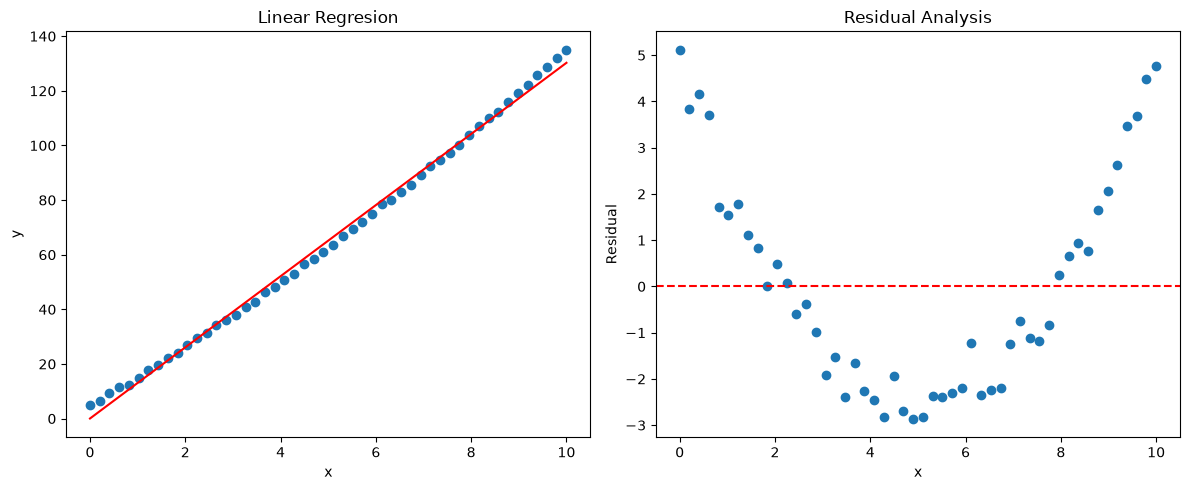

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))

# Linear regression
axes[0].scatter(x_test, y_test)
axes[0].plot(x_test, y_linear, color="red")
axes[0].set_title("Linear Regresion")
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")

# Residual analysis
axes[1].scatter(x_test, residuals_test)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residual Analysis")
axes[1].set_xlabel("x")
axes[1].set_ylabel("Residual")

plt.tight_layout()
plt.show()

In [4]:
# Fit a second-degree polynomial
coefficients = np.polyfit(x_test, y_test, 2)
a, b, c = coefficients

print(f"a: {a:.4f}")
print(f"b: {b:.4f}")
print(f"c: {c:.4f}")

a: 0.2974
b: 10.0485
c: 4.8903


In [6]:
# Evaluate the polynomial
y_quadratic = np.polyval(coefficients, x_test)

# Calculate residuals
residuals_quad = y_test - y_quadratic

# Calculate performance metrics
sse_quad = np.sum(residuals_quad**2)

sst = np.sum((y_test - np.mean(y_test))**2)

r2_quad = 1 - sse_quad / sst
rmse_quad = np.sqrt(np.mean(residuals_quad**2))

print(f"R-squared: {r2_quad:.4f}")
print(f"RMSE: {rmse_quad:.4f}")

R-squared: 0.9999
RMSE: 0.3739


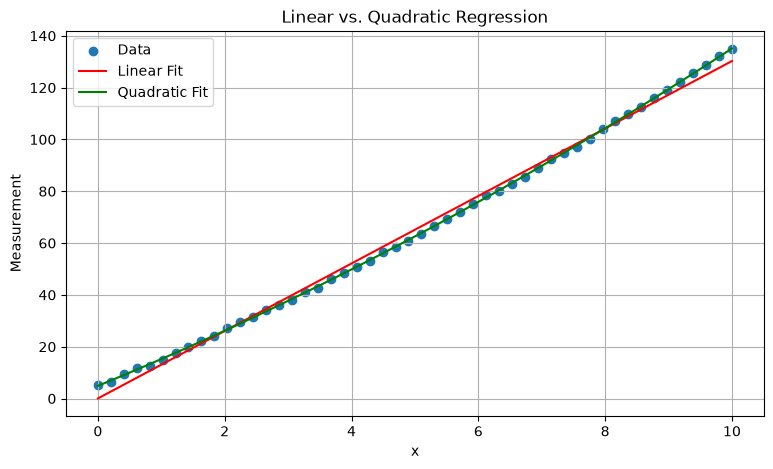

In [8]:
plt.figure(figsize=(9, 5))

plt.scatter(x_test, y_test, label="Data")

plt.plot(x_test, y_linear,
         color="red", label="Linear Fit")
plt.plot(x_test, y_quadratic,
         color="green", label="Quadratic Fit")

plt.xlabel("x")
plt.ylabel("Measurement")
plt.title("Linear vs. Quadratic Regression")
plt.legend()
plt.grid(True)
plt.show()

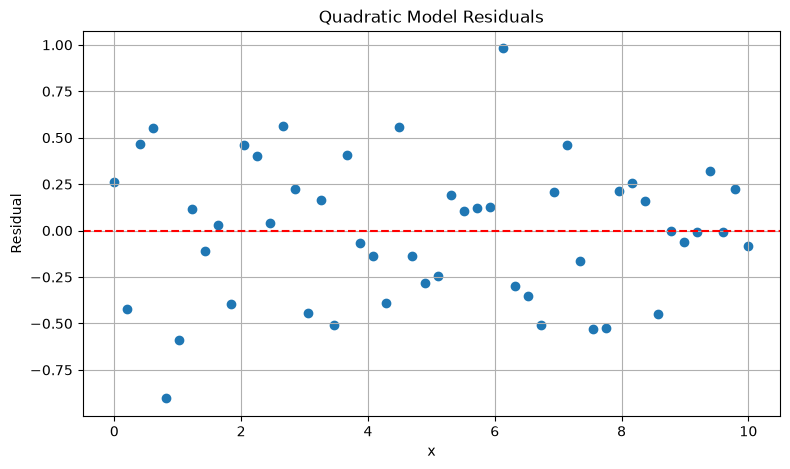

In [9]:
plt.figure(figsize=(9, 5))

plt.scatter(x_test, residual_quad)

plt.axhline(0, color="red", linestyle="--")

plt.xlabel("x")
plt.ylabel("Residual")
plt.title("Quadratic Model Residuals")
plt.grid(True)
plt.show()